# Introducao - O projeto tem como objetivo aplicar técnicas de modelagem supervisionada para prever e analisar o número de visitantes do zoológico Korkeasaari em 2023.
A análise segue a metodologia CRISP-DM, composta por etapas bem definidas:
Coleta de dados
Análise exploratória
Pré-processamento
Modelagem (KNN e Regressão Linear)
Validação (Hold-out)
Avaliação dos modelos
Inclusão de uma nova feature (“smoker”)
A ideia é transformar dados brutos em informações úteis e construir modelos capazes de fazer previsões numéricas (regressão) e classificações (nível de visitação), explorando também técnicas de visualização.

# 1. Importacoes basicas
Explicação:
pandas → manipulação e leitura de dados.
numpy → cálculos numéricos e vetoriais.
matplotlib.pyplot e seaborn → visualizações e gráficos.
sklearn → divisão dos dados, padronização e criação dos modelos (KNN, Regressão Linear etc).
warnings → apenas para ignorar mensagens de alerta desnecessárias.

In [ ]:
# ===============================================================
# FLEXMEDIA - PIPELINE CRISP-DM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report)
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

possible_paths = [
    Path("/content/Korkeasaari_kavijatilasto_2023.xlsx"),
    Path("/mnt/data/Korkeasaari_kavijatilasto_2023.xlsx"),
]
data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("❌ Faça upload do arquivo 'Korkeasaari_kavijatilasto_2023.xlsx' antes de rodar o código!")

print("✅ Arquivo encontrado em:", data_path)

# Leitura inicial
df_raw = pd.read_excel(data_path, header=None)
print("Dimensão do arquivo:", df_raw.shape)
display(df_raw.head(10))

print("===== FLEXMEDIA - TOTEM INTELIGENTE (Pipeline CRISP-DM) =====\n")


✅ Arquivo encontrado em: /content/Korkeasaari_kavijatilasto_2023.xlsx
Dimensão do arquivo: (41, 4)


,0,1,2,3
0,NaN,NaN,NaN,NaN
1,KORKEASAAREN ELÄINTARHA,NaN,NaN,KÄVIJÄTILASTO 2023
2,NaN,NaN,NaN,NaN
3,Tammikuu,NaN,NaN,Käynnit yhteensä
4,NaN,NaN,NaN,NaN
5,1,su,NaN,1985
6,2,ma,NaN,1315
7,3,ti,NaN,844
8,4,ke,NaN,1165
9,5,to,NaN,689


===== FLEXMEDIA - TOTEM INTELIGENTE (Pipeline CRISP-DM) =====



# 2. Coleta de dados
Aqui os dados do arquivo Korkeasaari_kavijatilasto_2023.xlsx são carregados.
Após a leitura, os dados são organizados e salvos em um formato padrão contendo:
Data do registro
Dia da semana
Número de visitantes

In [ ]:
month_map = {
    "tammikuu": 1, "helmikuu": 2, "maaliskuu": 3, "huhtikuu": 4, "toukokuu": 5,
    "kesäkuu": 6, "heinäkuu": 7, "elokuu": 8, "syyskuu": 9,
    "lokakuu": 10, "marraskuu": 11, "joulukuu": 12
}

rows = []
current_month = None
year = 2023

for idx, row in df_raw.iterrows():
    a = str(row[0]).strip().lower() if not pd.isna(row[0]) else ""
    b = str(row[1]).strip() if not pd.isna(row[1]) else ""
    val = row[3] if len(row) > 3 else None

    if a in month_map:
        current_month = month_map[a]
        continue

    try:
        day = int(float(a))
        visitors = int(float(val))
        date = pd.Timestamp(year=year, month=current_month, day=day)
        rows.append({"date": date, "weekday": b, "visitors": visitors})
    except:
        continue

data = pd.DataFrame(rows)
data = data.sort_values("date").reset_index(drop=True)
print("\n✅ Dados extraídos com sucesso:", len(data), "linhas")
display(data.head())


✅ Dados extraídos com sucesso: 31 linhas


,date,weekday,visitors
0,2023-01-01,su,1985
1,2023-01-02,ma,1315
2,2023-01-03,ti,844
3,2023-01-04,ke,1165
4,2023-01-05,to,689


# 3. Analise de dados
A análise exploratória ajuda a entender o comportamento dos dados antes de aplicar qualquer modelo.
São realizadas algumas visualizações e cálculos estatísticos:
.describe() → mostra média, desvio padrão e valores máximos e mínimos.
Gráfico de linha temporal → mostra a variação dos visitantes ao longo do ano.
Histograma → mostra a frequência de visitação (alta, média ou baixa).


--- ANÁLISE INICIAL ---
Período: 2023-01-01 00:00:00 → 2023-01-31 00:00:00
Estatísticas descritivas:


,visitors
count,31.000000
mean,490.129032
std,571.499766
min,21.000000
25%,66.000000
50%,219.000000
75%,728.500000
max,1985.000000


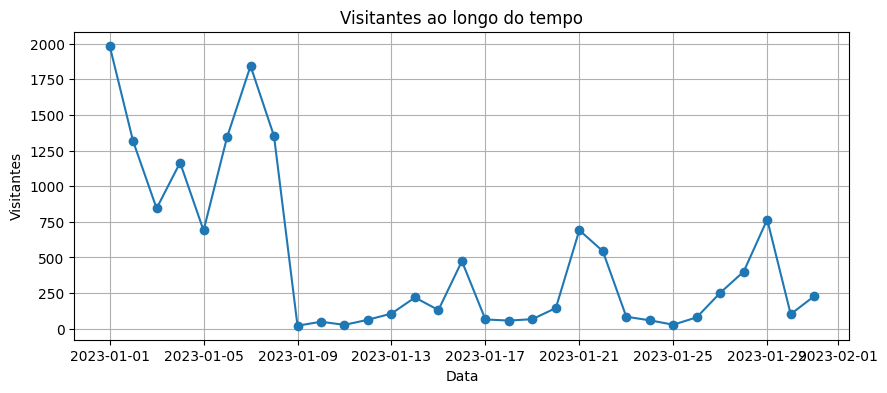

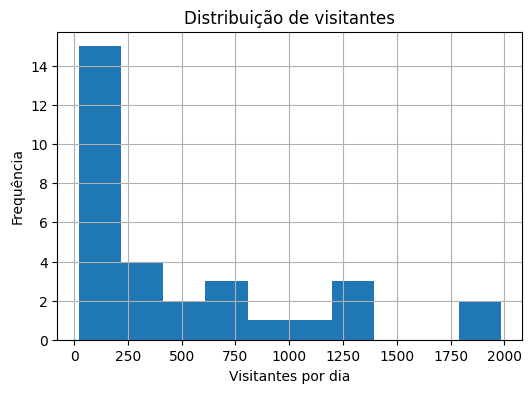

In [ ]:
print("\n--- ANÁLISE INICIAL ---")
print("Período:", data["date"].min(), "→", data["date"].max())
print("Estatísticas descritivas:")
display(data["visitors"].describe())

plt.figure(figsize=(10, 4))
plt.plot(data["date"], data["visitors"], marker='o')
plt.title("Visitantes ao longo do tempo")
plt.xlabel("Data")
plt.ylabel("Visitantes")
plt.grid(True)
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(data["visitors"], bins=10)
plt.title("Distribuição de visitantes")
plt.xlabel("Visitantes por dia")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

# 4. Pre processamento
Etapas realizadas:
Extração de informações da data
Dia, mês e dia da semana.
Criação de variáveis auxiliares
is_weekend: indica se é final de semana.
is_holiday: indica se é feriado.
season: estação do ano (inverno, primavera, verão, outono).
Criação da variável sintética smoker
Valor aleatório (0 = não, 1 = sim), apenas para demonstrar como adicionar uma nova feature.
Após essa preparação, os dados estão prontos para os modelos.

In [ ]:
df = data.copy()
df["day"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["dayofweek"] = df["date"].dt.dayofweek
df["is_weekend"] = df["dayofweek"].isin([5, 6]).astype(int)

# Estação (aproximação)
def month_to_season(m):
    if m in [12, 1, 2]: return "winter"
    if m in [3, 4, 5]: return "spring"
    if m in [6, 7, 8]: return "summer"
    return "autumn"

df["season"] = df["month"].apply(month_to_season)

# Feriados simples
feriados = ["01-01", "05-01", "12-25", "12-26"]
df["is_holiday"] = df["date"].dt.strftime("%m-%d").isin(feriados).astype(int)

# Feature 'smoker' (sintética para demonstração)
np.random.seed(42)
df["smoker"] = np.random.choice([0, 1], size=len(df), p=[0.8, 0.2])

display(df.head(10))

,date,weekday,visitors,day,month,dayofweek,is_weekend,season,is_holiday,smoker
0,2023-01-01,su,1985,1,1,6,1,winter,1,0
1,2023-01-02,ma,1315,2,1,0,0,winter,0,1
2,2023-01-03,ti,844,3,1,1,0,winter,0,0
3,2023-01-04,ke,1165,4,1,2,0,winter,0,0
4,2023-01-05,to,689,5,1,3,0,winter,0,0
5,2023-01-06,pe,1343,6,1,4,0,winter,0,0
6,2023-01-07,la,1843,7,1,5,1,winter,0,0
7,2023-01-08,su,1351,8,1,6,1,winter,0,1
8,2023-01-09,ma,21,9,1,0,0,winter,0,0
9,2023-01-10,ti,49,10,1,1,0,winter,0,0


#5. Divisão dos dados – Validação Hold-out
Os dados são divididos em duas partes:
Treinamento (80%) → usados para ensinar o modelo.
Teste (20%) → usados para avaliar o desempenho em dados novos.

In [ ]:
X = df[["day", "month", "dayofweek", "is_weekend", "is_holiday", "smoker"]]
y = df["visitors"]

# Divisão treino/teste (hold-out)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nValidação Hold-out → treino:", len(X_train), "teste:", len(X_test))

# Padronização
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Treino KNN
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)

# Avaliação
mae_knn = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))  # ✅ corrigido
r2_knn = r2_score(y_test, y_pred_knn)



Validação Hold-out → treino: 24 teste: 7


#6. Modelagem com KNN Regressão
Etapas:
Normalização dos dados com StandardScaler.
Criação do modelo: KNeighborsRegressor(n_neighbors=3).
Treinamento e teste do modelo.
Cálculo das métricas:
MAE (Mean Absolute Error) → erro médio absoluto.
RMSE (Root Mean Squared Error) → raiz do erro quadrático médio (corrigido).
R² → mede o quanto o modelo explica os dados.


--- KNN REGRESSOR ---
MAE = 186.43
RMSE = 239.11
R² = -0.886


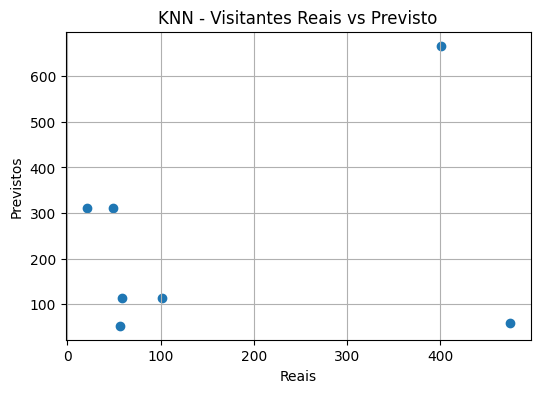

In [ ]:
print("\n--- KNN REGRESSOR ---")
print(f"MAE = {mae_knn:.2f}")
print(f"RMSE = {rmse_knn:.2f}")
print(f"R² = {r2_knn:.3f}")

plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred_knn)
plt.title("KNN - Visitantes Reais vs Previsto")
plt.xlabel("Reais")
plt.ylabel("Previstos")
plt.grid(True)
plt.show()

lr = LinearRegression()
lr.fit(X_train_s, y_train)
y_pred_lr = lr.predict(X_test_s)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)


#7. Modelagem com Regressão Linear
Etapas:
Treinamento com LinearRegression().
Predição nos dados de teste.
Avaliação com as mesmas métricas (MAE, RMSE, R²).
Gráfico de comparação entre valores reais e previstos.

In [ ]:
print("\n--- REGRESSÃO LINEAR ---")
print(f"MAE = {mae_lr:.2f}")
print(f"RMSE = {rmse_lr:.2f}")
print(f"R² = {r2_lr:.3f}")

coef = pd.DataFrame({"Feature": X.columns, "Coeficiente": lr.coef_})
display(coef)

q1, q2 = df["visitors"].quantile([0.33, 0.66])
def visitor_level(v):
    if v <= q1: return "Baixa"
    elif v <= q2: return "Média"
    return "Alta"

df["vis_level"] = df["visitors"].apply(visitor_level)

Xc = df[["day", "month", "dayofweek", "is_weekend", "is_holiday", "smoker"]]
yc = df["vis_level"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42)
Xc_train_s = scaler.fit_transform(Xc_train)
Xc_test_s = scaler.transform(Xc_test)

encoder = LabelEncoder()
yc_train_enc = encoder.fit_transform(yc_train)
yc_test_enc = encoder.transform(yc_test)

knn_clf = KNeighborsClassifier(n_neighbors=3)
knn_clf.fit(Xc_train_s, yc_train_enc)
yc_pred_enc = knn_clf.predict(Xc_test_s)
yc_pred = encoder.inverse_transform(yc_pred_enc)

# Métricas
acc = accuracy_score(yc_test_enc, yc_pred_enc)
prec = precision_score(yc_test_enc, yc_pred_enc, average="weighted", zero_division=0)
rec = recall_score(yc_test_enc, yc_pred_enc, average="weighted", zero_division=0)
cm = confusion_matrix(yc_test_enc, yc_pred_enc)



--- REGRESSÃO LINEAR ---
MAE = 265.72
RMSE = 369.92
R² = -3.513


,Feature,Coeficiente
0,day,-3.468702e+02
1,month,1.421085e-14
2,dayofweek,-4.861798e+01
3,is_weekend,2.430194e+02
4,is_holiday,1.194046e+02
5,smoker,-2.387976e+01


#8. Classificação com KNN (KNN Classifier)
Agora o problema é transformado em classificação, categorizando os dias em:
Baixa visitação
Média visitação
Alta visitação
A divisão é feita pelos tercis (33% e 66%) da variável visitors.
Em seguida, o modelo KNN Classifier é treinado para prever o nível de visitação.
Métricas avaliadas:
Acurácia → percentual de acertos.
Precisão e Revocação → qualidade das previsões por classe.
Matriz de confusão → mostra os erros e acertos em cada categoria.


--- KNN CLASSIFIER ---
Acurácia = 0.571
Precisão = 0.643
Revocação = 0.571


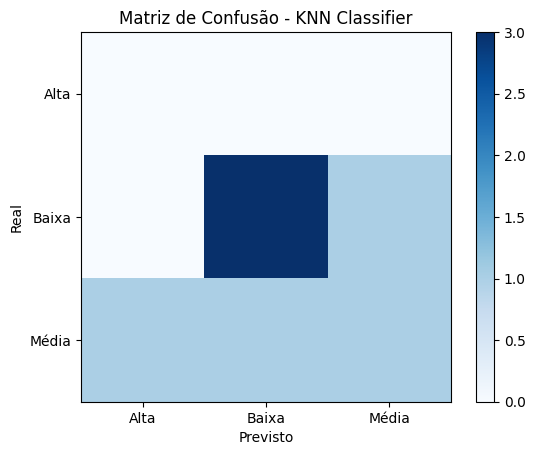


Relatório de classificação:
              precision    recall  f1-score   support

        Alta       0.00      0.00      0.00         0
       Baixa       0.75      0.75      0.75         4
       Média       0.50      0.33      0.40         3

    accuracy                           0.57         7
   macro avg       0.42      0.36      0.38         7
weighted avg       0.64      0.57      0.60         7



In [ ]:
print("\n--- KNN CLASSIFIER ---")
print(f"Acurácia = {acc:.3f}")
print(f"Precisão = {prec:.3f}")
print(f"Revocação = {rec:.3f}")

plt.imshow(cm, cmap="Blues")
plt.title("Matriz de Confusão - KNN Classifier")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.xticks(range(3), encoder.classes_)
plt.yticks(range(3), encoder.classes_)
plt.colorbar()
plt.show()

print("\nRelatório de classificação:")
print(classification_report(yc_test_enc, yc_pred_enc, target_names=encoder.classes_))

In [ ]:
print("\n===== CONCLUSÕES =====")
print(f"KNN Regressão → MAE: {mae_knn:.2f}, RMSE: {rmse_knn:.2f}, R²: {r2_knn:.3f}")
print(f"Regressão Linear → MAE: {mae_lr:.2f}, RMSE: {rmse_lr:.2f}, R²: {r2_lr:.3f}")
print(f"KNN Classifier → Acurácia: {acc:.3f}")
print("\nSugestões:")
print("- Incluir dados de clima e feriados reais pode melhorar o modelo.")
print("- A variável 'smoker' é sintética (criada apenas para demonstração).")
print("- Os modelos podem ser ajustados com mais dados históricos.")
print("==============================================================")


===== CONCLUSÕES =====
KNN Regressão → MAE: 186.43, RMSE: 239.11, R²: -0.886
Regressão Linear → MAE: 265.72, RMSE: 369.92, R²: -3.513
KNN Classifier → Acurácia: 0.571

Sugestões:
- Incluir dados de clima e feriados reais pode melhorar o modelo.
- A variável 'smoker' é sintética (criada apenas para demonstração).
- Os modelos podem ser ajustados com mais dados históricos.
